<a href="https://colab.research.google.com/github/aalitorres/002_A2026_Artificial_Intelligence/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Assignment 5.- Convolutional Neural Network**

**Artificial Intelligence**

**Professor:** MSc. Daniel Isaías López Páez

**Degree:** Biomedical Engineering

**Team Members**


* **Alisson Michelle Sepúlveda Torres** — 2115253
* **María Fernanda Tinoco Lopez** — 2103898
* **Mariana Vázquez De León** — 2114697
* **Valeria Cruz Gálvez** — 2001021

**Group:** 002

**Schedule:** Thursday N4–N6

**Classroom:** 12205

**1. Load libraries**

The required libraries are imported to work with the MNIST dataset, handle numerical data, and build the Convolutional Neural Network using TensorFlow and Keras.

In [7]:
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

**2. Load data**

The MNIST dataset contains images of handwritten digits from 0 to 9. The `load_data()` function is used to obtain the training and testing datasets, along with their corresponding labels. The dimensions of both datasets are also displayed.

In [8]:
(train_data, train_labels), (test_data, test_labels) = mnist.load_data()

print('Train data shape:', train_data.shape)
print('Test data shape:', test_data.shape)

Train data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


**3. Data preprocessing**

Before training, the images need to be prepared. Pixel values are normalized to a range between 0 and 1. The images are also reshaped to include an additional dimension representing the grayscale channel required by the convolutional layers.

In [9]:
train_data = train_data / 255.0
test_data = test_data / 255.0

train_data = train_data.reshape(-1, 28, 28, 1)
test_data = test_data.reshape(-1, 28, 28, 1)

print('Processed train shape:', train_data.shape)
print('Processed test shape:', test_data.shape)

Processed train shape: (60000, 28, 28, 1)
Processed test shape: (10000, 28, 28, 1)


**4. Model selection and training**

A Convolutional Neural Network is created using the Sequential model. Its architecture consists of convolutional layers to extract image features, pooling layers to reduce dimensions, and Dense layers to perform classification. The output layer contains 10 neurons, representing the digits from 0 to 9, with the Softmax activation function.

In [10]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

The model is compiled by defining the optimizer, loss function, and evaluation metric. Adam is selected as the optimizer, Sparse Categorical Crossentropy as the loss function, and Accuracy as the evaluation metric.

In [11]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

The training process is performed using the training images and their corresponding labels. The model is trained for 8 epochs with a batch size of 32.

In [12]:
model.fit(train_data, train_labels, epochs=8, batch_size=32)

Epoch 1/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 27ms/step - accuracy: 0.9569 - loss: 0.1412
Epoch 2/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - accuracy: 0.9859 - loss: 0.0464
Epoch 3/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9901 - loss: 0.0319
Epoch 4/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9927 - loss: 0.0238
Epoch 5/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9943 - loss: 0.0179
Epoch 6/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9957 - loss: 0.0133
Epoch 7/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9958 - loss: 0.0117
Epoch 8/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9969 - loss: 0.0099


**5. Model testing**

After training, the model is evaluated using the test dataset. The `evaluate()` function calculates the loss and accuracy, allowing its classification performance to be measured on previously unseen images.

In [15]:
loss, accuracy = model.evaluate(test_data, test_labels)

print('Test loss:', loss)
print('Test accuracy:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9913 - loss: 0.0304
Test loss: 0.03044554963707924
Test accuracy: 0.9912999868392944


Finally, five predictions are performed using images from the test dataset. The predicted digits are displayed alongside their actual labels to compare the classification results.

In [16]:
predictions = model.predict(test_data[:5])

for i in range(5):
    prediction = np.argmax(predictions[i])
    actual = test_labels[i]

    print('Sample:', i + 1)
    print('Predicted:', prediction)
    print('Actual:', actual)
    print('--------------------')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Sample: 1
Predicted: 7
Actual: 7
--------------------
Sample: 2
Predicted: 2
Actual: 2
--------------------
Sample: 3
Predicted: 1
Actual: 1
--------------------
Sample: 4
Predicted: 0
Actual: 0
--------------------
Sample: 5
Predicted: 4
Actual: 4
--------------------


To visualize the classification results, the five test images are displayed alongside their predicted and actual labels. This provides a visual comparison to verify the model's predictions.

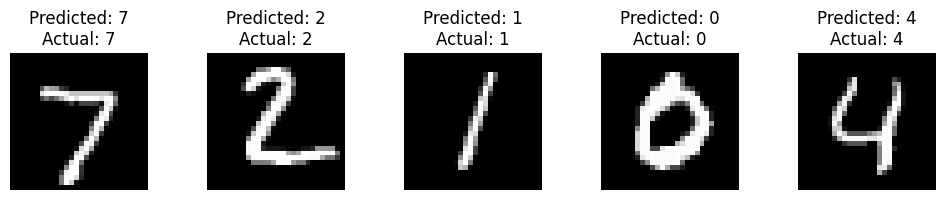

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].reshape(28, 28), cmap='gray')
    plt.title(f'Predicted: {np.argmax(predictions[i])}\nActual: {test_labels[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()